# Water Rights Restored to the Gila River

The impacts of irrigation on vegetation health in the Gila River Valley

## Set up: import libraries

We’ll need some Python libraries to complete this workflow.

In the cell below, making sure to keep the packages in order, add packages for:

- Working with DataFrames  
- Working with GeoDataFrames  
- Making interactive plots of tabular and vector data


### Reflect and Respond #1: 
What are we using the rest of these packages for? See if you can figure it out as you complete the notebook.

Rasters and multidimensional plots

In [13]:
### working with dataframes
import pandas as pd

### working with geodataframes
import geopandas as gpd

### making interactive plots of tabular and vector data
import hvplot.pandas
import geoviews
import holoviews
import hvplot
import bokeh
import matplotlib.pyplot as plt

# fixing key error with lon_0
import cartopy

### work with json data
import json

### work with pattern matching rules for pathnames 
from glob import glob

### access the data we'll use for the assignment
import earthpy

### interactive plots with rasters 
import hvplot.xarray

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

## Step 1: Download sample data

In this analysis, you’ll need to download multiple data files to your computer. You’ll need to set up a folder/directory for the files, and while you’re at it, download the sample data there.

In the cell below, replace ‘Project Name’ with ‘Gila River Vegetation' and 'my-data-folder' with a **descriptive** directory name.

In [2]:
### define the project and data
project = earthpy.Project(
    'Gila River Vegetation', dirname = 'vegetation')

### get the data
project.get_data()

### Earth Data Science data formats:

| Data type | Descriptions | Common file formats | Python type |
|------------------|------------------|------------------|------------------|
| Time Series | The same data points (e.g. streamflow) collected multiple times over time | Tabular formats (e.g. .csv, or .xlsx) | pandas DataFrame |
| Vector | Points, lines, and polygons (with coordinates) | Shapefile (often an archive like a `.zip` file because a Shapefile is actually a collection of at least 3 files) | geopandas GeoDataFrame |
| Raster | Evenly spaced spatial grid (with coordinates) | GeoTIFF (`.tif`), NetCDF (`.nc`), HDF (`.hdf`) | rioxarray DataArray |

Read more about [vector](https://www.earthdatascience.org/courses/use-data-open-source-python/intro-vector-data-python/spatial-data-vector-shapefiles/) and [raster](https://earthdatascience.org/courses/intro-to-earth-data-science/file-formats/use-spatial-data/use-raster-data/) data in the Earth Data Science textbook.

### Reflect and Respond #2:
For this coding challenge, we are interested in the boundary of the Gila River Indian Community, and the health of vegetation in the area measured on a scale from -1 to 1. In the cell below, answer the following questions: What data type do you think the boundary will be? What about the vegetation health?

Boundary should be vector, as boudaries are typically polygons. Vegetation health is likely raster. LC/LU and NDVI are all raster based.

## Step 2: Make a site map

### Step 2A: Load the Gila River Indian Community boundary  

- Locate the Tribal Subdivision files in your download directory  
- Change `'subdivision-directory'` to the actual location
- Load the data into Python and check that it worked


In [3]:
### figure out where the download lives
print(project.project_dir)

C:\Users\taugi\AppData\Local\earth-analytics\earth-analytics\vegetation


In [4]:
### load in the boundary data
aitsn_gdf = gpd.read_file(project.project_dir / 'tl_2020_us_aitsn/tl_2020_us_aitsn.shp')

### check that it worked
aitsn_gdf

,AIANNHCE,TRSUBCE,TRSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,2430,653,02419073,2430653,Red Valley,Red Valley Chapter,T2,D7,G2300,A,922036695,195247,+36.6294607,-109.0550394,"POLYGON ((-109.2827 36.64644, -109.28181 36.65..."
1,2430,665,02419077,2430665,Rock Point,Rock Point Chapter,T2,D7,G2300,A,720360268,88806,+36.6598701,-109.6166836,"POLYGON ((-109.85922 36.49859, -109.85521 36.5..."
2,2430,675,02419081,2430675,Rough Rock,Rough Rock Chapter,T2,D7,G2300,A,364475668,216144,+36.3976971,-109.7695183,"POLYGON ((-109.93053 36.40672, -109.92923 36.4..."
3,2430,325,02418975,2430325,Indian Wells,Indian Wells Chapter,T2,D7,G2300,A,717835323,133795,+35.3248534,-110.0855000,"POLYGON ((-110.24222 35.36327, -110.24215 35.3..."
4,2430,355,02418983,2430355,Kayenta,Kayenta Chapter,T2,D7,G2300,A,1419241065,1982848,+36.6884391,-110.3045616,"POLYGON ((-110.56817 36.73489, -110.56603 36.7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
479,1310,100,02418907,1310100,1,District 1,28,D7,G2300,N,139902197,0,+33.0600842,-111.5806313,"POLYGON ((-111.63622 33.11798, -111.63405 33.1..."
480,4290,550,02612186,4290550,Mission Highlands,Mission Highlands,00,D7,G2300,N,6188043,0,+48.0754384,-122.2507432,"POLYGON ((-122.27579 48.07128, -122.27578 48.0..."
481,0855,400,02418941,0855400,Fort Thompson,Fort Thompson District,07,D7,G2300,N,535432708,38653364,+44.1559680,-099.4467700,"POLYGON ((-99.66452 44.25269, -99.66449 44.255..."
482,0335,300,02784108,0335300,Indian Point,Indian Point Segment,T3,D7,G2300,N,326985,0,+48.0604594,-092.8466753,"POLYGON ((-92.85187 48.05944, -92.85186 48.059..."


You might notice in this dataset that some of the names are not easily searchable. For example, the Gila River subdivisions are named “District 1-7”! So, how do we know what to search for? We recommend making an **interactive** plot of the data so that you can find the information you need:

In [5]:
print(aitsn_gdf.crs)
print(aitsn_gdf.total_bounds)

EPSG:4269
[-124.093168   31.507858  -83.156218   48.63591 ]


In [12]:
### make an interactive map

## esri imagery is not compatible with 4269 for some reason
## update: still can't fix key error
'''aitsn_gdf.to_crs(epsg=3857).hvplot(

    ### set basemap
    geo = True, tiles = 'EsriImagery', 

    ### set figure size
    frame_width = 500,

    ### other map parameters
    legend = False, fill_color = None, edge_color = 'white',

    ### make all the column values in the dataset visible
    hover_cols = 'all')'''


# issues using explore
'''aitsn_gdf.to_crs(epsg=3857).explore(
    tiles = 'Esri.WorldImagery',
    color = 'white',
    style_kwds = {'fillOpacity': 0, 'weight': 1},
    tooltip = ['NAME', 'AIANNHCE'])'''


# just using folium
import folium
m = folium.Map(location=[33.5, -111.9], zoom_start=8)

# basemap here
folium.TileLayer(
    tiles = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr = 'Esri',
    name = 'Satellite').add_to(m)

'''folium.TileLayer('OpenStreetMap', 
                 name='OpenStreetMap'
                 ).add_to(m)'''

# boundary polygon
folium.GeoJson(
    aitsn_gdf,
    name = 'Gila River Community',
    style_function = lambda feature: {
        'fillOpacity': 0,
        'color': 'white',
        'weight': 1},
    tooltip = folium.GeoJsonTooltip(fields=['NAME', 'AIANNHCE'])).add_to(m)
m.save("map1.html")

### Reflect and Respond #3:
What column could you use to uniquely identify the subdivisions of the reservation you want to study using this interactive map? What value do you need to use to filter the `GeoDataFrame`?

First pass:
The 'NAME' Column works best for identifying the unique reservations to study. The Gila River Indian Reservation polygons all have numbers for NAMEs, a simply filter out non-numeric entries:

In [21]:
name_num = pd.to_numeric(aitsn_gdf['NAME'], errors='coerce').notna()
# this didn't work, so I consulted the wikipedia page: https://upload.wikimedia.org/wikipedia/commons/f/f8/Indian_Tribal_Reservations_in_Arizona.png?utm_source=en.wikipedia.org&utm_campaign=imageinfo&utm_content=original
# and then google maps: https://maps.app.goo.gl/1ji9oZ5StnpEBshS7
long_w = pd.to_numeric(aitsn_gdf['INTPTLON'], errors='coerce') < -111
aitsn_gdf.loc[name_num]

,AIANNHCE,TRSUBCE,TRSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
89,0605,500,02418916,0605500,5,District 5,28,D7,G2300,N,39044530,52807,+45.0119294,-101.1850029,"POLYGON ((-101.23905 45.03772, -101.23894 45.0..."
90,0605,600,02418918,0605600,6,District 6,28,D7,G2300,N,2629990300,326123906,+45.0717586,-100.6105858,"POLYGON ((-100.89394 45.01476, -100.89379 45.0..."
109,5590,075,02418885,5590075,1,County District 1,TC,D7,G2300,S,1557681560,48518898,+33.8689468,-094.7827386,"POLYGON ((-95.1567 33.94674, -95.15662 33.9534..."
130,5590,300,02418891,5590300,4,County District 4,TC,D7,G2300,S,1819552523,28954710,+35.0450792,-094.7168952,"POLYGON ((-95.05992 34.76863, -95.05991 34.769..."
214,5590,150,02418889,5590150,2,County District 2,TC,D7,G2300,S,2166517795,72598055,+34.1870585,-094.7132618,"POLYGON ((-95.04677 34.41936, -95.03977 34.419..."
215,5590,225,02418890,5590225,3,County District 3,TC,D7,G2300,S,2689608667,9360690,+34.6619077,-094.6767414,"POLYGON ((-95.05997 34.7501, -95.05997 34.7501..."
216,5590,525,02418894,5590525,7,County District 7,TC,D7,G2300,S,4047368572,81008274,+34.3970740,-095.3267603,"POLYGON ((-95.77952 34.16497, -95.77948 34.165..."
257,5590,675,02418896,5590675,9,County District 9,TC,D7,G2300,S,1334923326,17979934,+33.9715106,-096.1681738,"POLYGON ((-96.455 33.96065, -96.45444 33.96874..."
272,1310,200,02418909,1310200,2,District 2,28,D7,G2300,N,80067751,0,+33.0422261,-111.6615277,"POLYGON ((-111.68825 33.09898, -111.68683 33.1..."
273,1310,300,02418911,1310300,3,District 3,28,D7,G2300,N,150954569,90,+33.0544623,-111.7576177,"POLYGON ((-111.82434 33.07843, -111.82432 33.0..."


In [20]:
aitsn_gdf.loc[name_num & long_w]

,AIANNHCE,TRSUBCE,TRSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
272,1310,200,02418909,1310200,2,District 2,28,D7,G2300,N,80067751,0,+33.0422261,-111.6615277,"POLYGON ((-111.68825 33.09898, -111.68683 33.1..."
273,1310,300,02418911,1310300,3,District 3,28,D7,G2300,N,150954569,90,+33.0544623,-111.7576177,"POLYGON ((-111.82434 33.07843, -111.82432 33.0..."
274,1310,500,02418915,1310500,5,District 5,28,D7,G2300,N,222138531,184124,+33.0832674,-111.8702003,"POLYGON ((-111.99608 33.08808, -111.99608 33.0..."
318,1310,700,02418919,1310700,7,District 7,28,D7,G2300,N,141760925,0,+33.3131297,-112.2553081,"POLYGON ((-112.30867 33.38103, -112.30781 33.3..."
420,1310,400,02418913,1310400,4,District 4,28,D7,G2300,N,317456229,568147,+33.1807557,-111.8642246,"POLYGON ((-111.99557 33.27196, -111.99539 33.2..."
421,1310,600,02418917,1310600,6,District 6,28,D7,G2300,N,458764113,185175,+33.1903088,-112.0925376,"POLYGON ((-112.204 33.33508, -112.20364 33.341..."
479,1310,100,02418907,1310100,1,District 1,28,D7,G2300,N,139902197,0,+33.0600842,-111.5806313,"POLYGON ((-111.63622 33.11798, -111.63405 33.1..."


Eventually, I found that AIANNHCE might work...

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

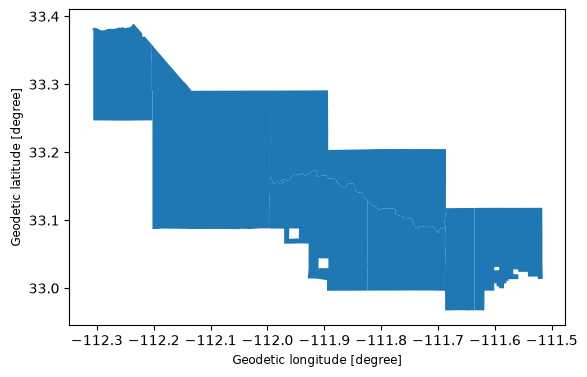

In [23]:
gila_subdivisions = aitsn_gdf.loc[aitsn_gdf['AIANNHCE'] == '1310']
gila_subdivisions.plot()

YAY! Fixed Folium map to show details on this category!

Now that you have the info you need, it’s also a good idea to check the data type. Are the values in the unique identifier column you've selected some kind of **number** or an **object** like a text string? We can’t tell just by looking, which is where the `.info()` method comes in:

In [24]:
aitsn_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   AIANNHCE  484 non-null    object  
 1   TRSUBCE   484 non-null    object  
 2   TRSUBNS   484 non-null    object  
 3   GEOID     484 non-null    object  
 4   NAME      484 non-null    object  
 5   NAMELSAD  484 non-null    object  
 6   LSAD      484 non-null    object  
 7   CLASSFP   484 non-null    object  
 8   MTFCC     484 non-null    object  
 9   FUNCSTAT  484 non-null    object  
 10  ALAND     484 non-null    int64   
 11  AWATER    484 non-null    int64   
 12  INTPTLAT  484 non-null    object  
 13  INTPTLON  484 non-null    object  
 14  geometry  484 non-null    geometry
dtypes: geometry(1), int64(2), object(12)
memory usage: 56.8+ KB


### Reflect and Respond #4:
What is the data type of the unique identifier column? How will that affect your code?

The data type is 'object'. The primary issue is recalling that it is stored as a string and not a number --> str()

## Step 2B: Select the Gila River subdivisions and make a site map.

- Replace `identifier` with the value you found from exploring the interactive map. Make sure that you are using the correct data type!  
- Change the plot to have a web tile basemap and add a title. Change the color of the Gila River Indian Community polygon so that it's transparent

In [31]:
### merge the Gila River subdivisions
gila_gdf = gila_subdivisions.dissolve()

### plot with imagery tiles and a transparent polygon
'''gila_gdf.hvplot(
    geo=True,
    tiles='EsriImagery',
    title='Gila River Indian Community',
    frame_width=700,
    fill_alpha=0,
    line_color='white',
    line_width=1
)'''

gila_gdf

,geometry,AIANNHCE,TRSUBCE,TRSUBNS,GEOID,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON
0,"POLYGON ((-111.6827 33.11763, -111.67251 33.11...",1310,200,02418909,1310200,2,District 2,28,D7,G2300,N,80067751,0,+33.0422261,-111.6615277


In [36]:
# still getting key errors, using folium:

# 33.177573,-112.2419429,10z
m = folium.Map(location=[33.18, -112], zoom_start=10)

# basemap here
folium.TileLayer(
    tiles = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr = 'Esri',
    name = 'Satellite').add_to(m)

folium.GeoJson(
    gila_gdf,
    name = 'Gila River Reservation',
    style_function = lambda feature: {
        'fillOpacity': 0,
        'color': 'white',
        'weight': 1},
    tooltip = folium.GeoJsonTooltip(fields=['NAME', 'AIANNHCE'])).add_to(m)
m.save("map3.html")

## Wrap up Steps 1-2

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [38]:
%store aitsn_gdf gila_gdf project

Stored 'aitsn_gdf' (GeoDataFrame)
Stored 'gila_gdf' (GeoDataFrame)
Stored 'project' (Project)


Finally, be sure to `Restart` and `Run all` to make sure your notebook works all the way through!